# សប្ដាហ៍ទី 6 · Objects និង lifecycle

សំណើមួយគឺច្រើនជាងទិន្នន័យ: វាមានដំណើរមួយ ចាប់ពីថ្មី រហូតដល់បានប្រគល់។ សប្ដាហ៍នេះ អ្នកអាន class ពិតមួយ បង្កើត object ហើយសរសេរវិធានដែលសម្រេចថា ការប្ដូរណាខ្លះត្រូវបានអនុញ្ញាត។

| | |
|---|---|
| **សំណួរសប្ដាហ៍នេះ** | តើប្រព័ន្ធរក្សារបស់នីមួយៗឱ្យនៅក្នុងស្ថានភាពសមហេតុផល ដោយរបៀបណា? |
| **Python ដែលអ្នកនឹងរៀន** | ការអាន class ការបង្កើត object, attribute, method, `self`; dictionary នៃការប្ដូរដែលបានអនុញ្ញាត (`dict` នៃ list, `in`) |
| **គោលការណ៍ទី 6** | **ធ្វើឱ្យស្ថានភាពខុស កើតឡើងបានពិបាក។** អនុញ្ញាតតែការប្ដូរណាដែលសមហេតុផល។ រក្សាវិធាននៅជាប់នឹងទិន្នន័យ។ |
| **ផ្នែកដែលអ្នកបង្កើត** | `can_move(old_status, new_status)`: វិធានដែលការប្ដូរ status គ្រប់ដង ត្រូវតែឆ្លងកាត់ |

*Campus FoodBridge ជាករណីប្រឌិត។ អង្គការ មនុស្ស និងលេខទាំងអស់ សុទ្ធតែប្រឌិតឡើង។*

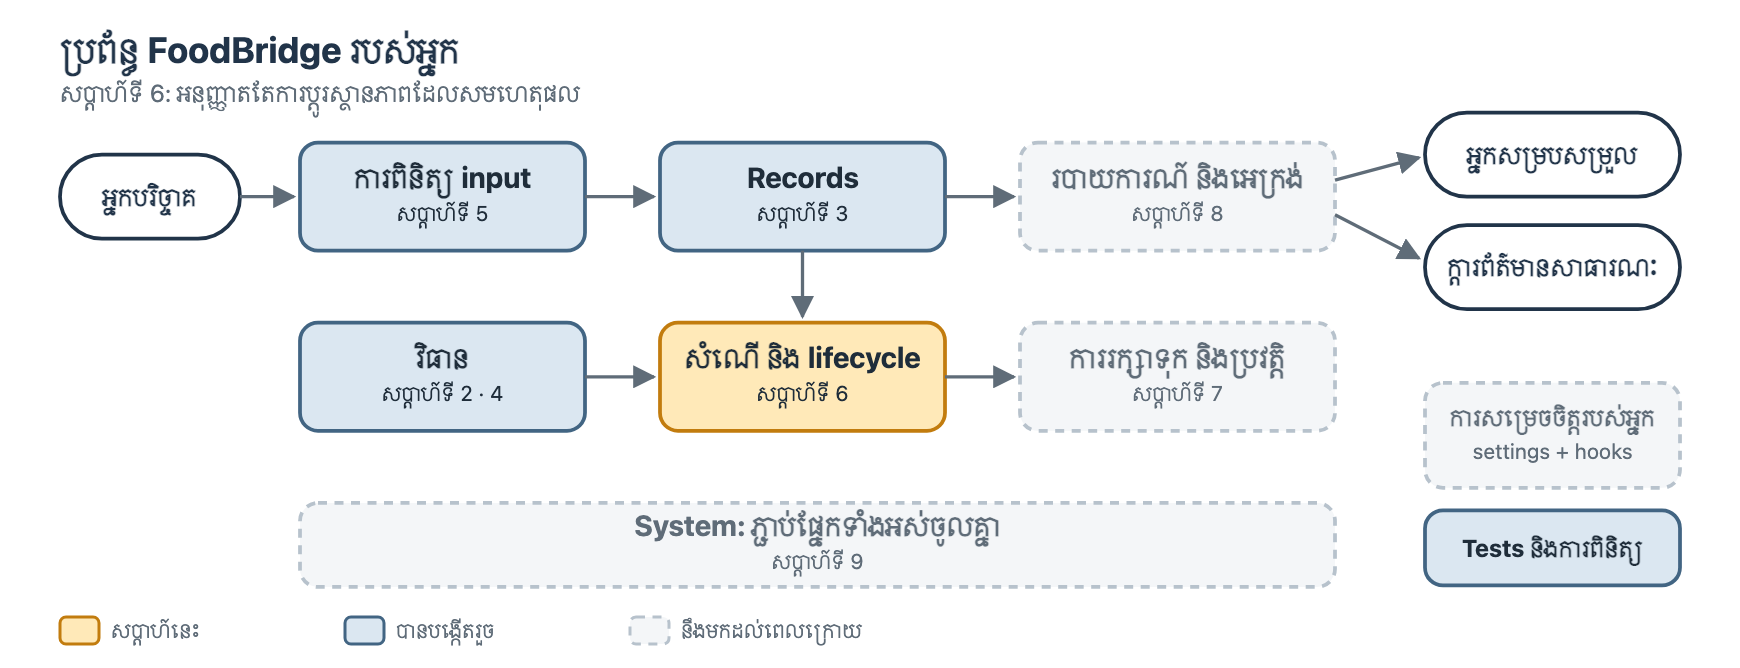

## មុនពេលចាប់ផ្ដើម

1. ចុចលើពាក្យ Copy to Drive (ឬ ចូលទៅកាន់ File រួចចុច Save a copy in Drive) រួចធ្វើការក្នុងច្បាប់ចម្លងរបស់អ្នក។
2. Run setup cell។ Run វាម្ដងទៀត ក្រោយពេល restart runtime។
3. ⭐ = កម្រិតមូលដ្ឋាន សម្រាប់គ្រប់គ្នា, ⭐⭐ = សម្រាប់សាកល្បងបន្ថែម។

In [ ]:
# @title ▶ សូម run cell នេះមុនគេ (setup) — វារៀបចំប្រព័ន្ធ FoodBridge
# វាដកយក (unpack) ប្រព័ន្ធរបស់វគ្គសិក្សា ដែលរក្សាទុកនៅក្នុង notebook នេះ។
# មិនត្រូវការ internet ឬ install អ្វីទេ។ សូម run វាម្ដងទៀត ក្រោយពេល Colab restart។
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("ឯកសាររបស់វគ្គសិក្សាក្នុង notebook នេះខូច។ សូមទាញយកច្បាប់ថ្មីមួយ។")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
bridge.set_language("km")     # screens and checks in Khmer
print("✅ ប្រព័ន្ធ FoodBridge រួចរាល់ហើយ (version " + bridge.KIT_VERSION + ")។ អ្នកអាចបន្តបាន។")


## ចាប់ផ្ដើមថ្នាក់ · ចែករំលែកកិច្ចការស្រាវជ្រាវទី 4 (10 នាទី)

ក្នុងក្រុមបីនាក់ ចែករំលែកប្រព័ន្ធដែលអ្នកបានស្រាវជ្រាវ។

1. តើ record មួយរក្សាទុកអ្វីខ្លះ ហើយវាប្រើ **ID** អ្វី?
2. ពេលមានអ្វីមួយ **ត្រូវបានកែតម្រូវ** តើ value ចាស់ត្រូវបានរក្សាទុក ត្រូវបានជំនួស ឬបង្ហាញថាជាការកែតម្រូវ? តើអ្នកដឹងដោយរបៀបណា?
3. តើនរណាត្រូវការ **ប្រវត្តិ** ហើយបើគ្មានវា តើអ្វីនឹងខុស?

📝 **គំនិតមួយពីមិត្តរួមថ្នាក់ ដែលខ្ញុំចង់ចងចាំ:**

## វគ្គទី 1 · រៀន: object និង lifecycle របស់វា (30 នាទី)

### គំនិតសំខាន់: entity, status និង workflow

គិតពីកញ្ចប់អីវ៉ាន់មួយដែលអ្នកកុម្ម៉ង់តាមអនឡាញ។ ប្រព័ន្ធរបស់ហាងតាមដានវា: *បានកុម្ម៉ង់ → បានផ្ញើចេញ → កំពុងដឹកមក → បានប្រគល់*។ កញ្ចប់អីវ៉ាន់គឺជា **entity**: របស់ពិតមួយដែលប្រព័ន្ធតាមដាន។ **status** របស់វាប្រាប់ថា វានៅត្រង់ណាក្នុងដំណើររបស់វា។ **workflow** គឺជាសំណុំនៃការប្ដូរដែលសមហេតុផល។ កញ្ចប់អីវ៉ាន់មិនអាចបានប្រគល់ មុនពេលវាត្រូវបានផ្ញើចេញទេ ហើយកញ្ចប់ដែលបានប្រគល់រួច មិនត្រឡប់ទៅជា "បានកុម្ម៉ង់" វិញទេ។

សំណើមួយមានដំណើរប្រភេទដូចគ្នានេះ:

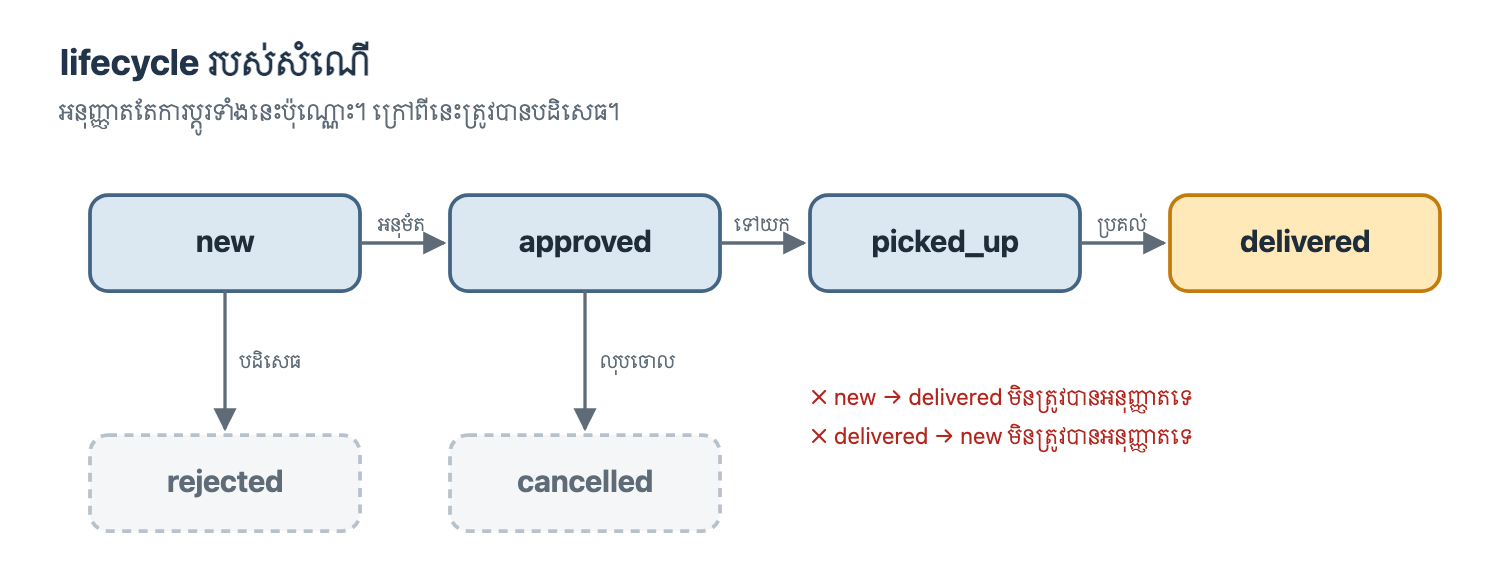

អ្នកសម្របសម្រួល **អនុម័ត** ឬ **បដិសេធ** សំណើថ្មី។ អ្នកស្ម័គ្រចិត្ត **ទៅយក** និង **ប្រគល់** អាហារដែលបានអនុម័ត។ ព្រួញនីមួយៗគឺជាការប្ដូរដែលបានអនុញ្ញាត។ ការប្ដូរផ្សេងទៀតទាំងអស់ត្រូវបានបដិសេធ។ rejected, cancelled និង delivered គឺជា **end state** (ស្ថានភាពចុងក្រោយ): គ្មានអ្វីប្ដូរចេញពីវាបានទេ។

### 1 · class គឺជាប្លង់ ហើយ object គឺជារបស់មួយ

រហូតមកដល់ពេលនេះ សំណើនីមួយៗជា dictionary មួយ។ **class** ទៅមុខមួយជំហានទៀត: វារក្សាទិន្នន័យ **និង** សកម្មភាពដែលជារបស់វា នៅជាមួយគ្នា។ class គឺជាប្លង់។ **object** នីមួយៗដែលបង្កើតចេញពីវា គឺជារបស់ពិតមួយ។

In [ ]:
class Parcel:
    def __init__(self, code, address):
        self.code = code
        self.address = address
        self.status = "ordered"

    def describe(self):
        return f"{self.code} to {self.address}: {self.status}"

parcel_a = Parcel("P01", "Battambang")
parcel_b = Parcel("P02", "Siem Reap")
print(parcel_a.describe())
print(parcel_b.describe())

- `class Parcel:` ចាប់ផ្ដើមប្លង់។ ឈ្មោះ class ចាប់ផ្ដើមដោយអក្សរធំ។
- `__init__` (សញ្ញា underscore ពីរនៅសងខាង) run ដោយស្វ័យប្រវត្តិ ពេលអ្នកបង្កើត object ដោយ `Parcel("P01", "Battambang")`។ វាកំណត់ value ចាប់ផ្ដើម។
- `self` មានន័យថា **object នេះ**។ `self.status = "ordered"` ផ្ដល់ status ផ្ទាល់ខ្លួនដល់កញ្ចប់នេះ។
- `describe` គឺជា **method**: function ដែលជារបស់ class។ អ្នកហៅវាដោយប្រើសញ្ញាចុច: `parcel_a.describe()`។ Python បំពេញ `self` ឱ្យអ្នក។

### 2 · attribute: object នីមួយៗរក្សាទិន្នន័យផ្ទាល់ខ្លួន

**attribute** គឺជា value ដែលរក្សាទុកនៅលើ object មួយ ដូចជា `parcel_a.status`។ អ្នកអានវាដោយប្រើសញ្ញាចុច។

🤔 **ទាយមើល** បន្ទាត់ចុងក្រោយ មុនពេលអ្នក run: តើការប្ដូរ `parcel_a` ក៏ប្ដូរ `parcel_b` ដែរឬទេ?

In [ ]:
print(parcel_a.code, parcel_a.status)
parcel_a.status = "shipped"
print(parcel_a.describe())
print(parcel_b.describe())

**ការទាយ:** …  **លទ្ធផល:** …

### 3 · អាន class ពិតមួយ: `bridge.Offer`

ក្នុងវគ្គសិក្សានេះ ភាគច្រើនអ្នកនឹង **អាន** class មិនមែនសរសេរ class ធំៗទេ។ ការអាន code គឺជាជំនាញដែលអ្នកត្រូវការ ដើម្បីវាយតម្លៃអ្វីដែលជំនួយការ AI ផ្ដល់ឱ្យអ្នក។ នេះគឺជា source code នៃ class `Offer` ផ្ទាល់របស់ kit។ (អ្នកអាចរំលង `to_record` បាន ព្រោះវាជារបស់សប្ដាហ៍ទី 7។)

In [ ]:
import inspect
print(inspect.getsource(bridge.Offer))

🤔 អាន class ហើយឆ្លើយ:

1. តើសំណើនីមួយៗមាន attribute អ្វីខ្លះ?
2. តើ status របស់សំណើថ្មីស្រឡាងគឺអ្វី? តើនរណាជាអ្នកសម្រេចរឿងនោះ?
3. តើ `move_to` ធ្វើអ្វី **មុនពេល** វាប្ដូរ status?

📝 **ចម្លើយរបស់ខ្ញុំ:**

<details><summary>មើលចម្លើយគំរូមួយ</summary>

1. `id`, `donor`, `contact`, `food`, `category`, `portions`, `hours_left`, `status` និង `partner`។
2. តែងតែ `"new"` ហើយមិនទាន់មានអង្គការដៃគូនៅឡើយ។ `__init__` ជាអ្នកសម្រេច មិនមែនមនុស្សដែលបង្កើតសំណើទេ ដូច្នេះសំណើគ្រប់មួយចាប់ផ្ដើមនៅដើមដំណើររបស់វា។
3. វាសួរវិធានមួយ: `is_allowed(self.status, new_status)`។ បើចម្លើយគឺ `False` វា return `False` ហើយមិនប្ដូរអ្វីទាំងអស់។ មានតែការប្ដូរដែលបានអនុញ្ញាតប៉ុណ្ណោះ ទើបប្ដូរ status។

</details>

### 4 · បង្កើតសំណើមួយ ហើយហៅ method របស់វា

`bridge.Offer(...)` run `__init__` ជាមួយ value របស់អ្នក។ បន្ទាប់មក អ្នកអាចអាន attribute និងហៅ method របស់វា។

In [ ]:
offer = bridge.Offer("F101", "Sunrise Bakery", "Bread rolls", "bread", 30, 5)
print(offer.describe())
print(offer.status, offer.is_open())

### 5 · Python មិនឃាត់អ្នកទេ

code ណាក៏អាចប្ដូរ attribute ណាមួយដោយផ្ទាល់បាន។ មើលថាមានអ្វីកើតឡើង ដោយសារការវាយខុសតែមួយ។

In [ ]:
offer.status = "deliverd"        # វាយខុស ហើយវារំលងគ្រប់ជំហាន
print(offer.describe())
print("open?", offer.is_open())

`"deliverd"` មិនមែនជា status ពិតទេ។ សំណើនេះមិន open (មិនទាន់បញ្ចប់) ទេ ដូច្នេះវាបាត់ពីបញ្ជីរបស់អ្នកសម្របសម្រួល។ វាក៏មិនមែនជា `"delivered"` ដែរ ដូច្នេះវាមិនត្រូវបានរាប់ជាបានប្រគល់ទេ។ នំបុ័ងនោះគ្រាន់តែបាត់ពីរបាយការណ៍ទាំងអស់។

ត្រូវនិយាយឱ្យត្រង់អំពីរឿងនេះ: **Python មិនអាចធ្វើឱ្យស្ថានភាពខុស ក្លាយជារឿងមិនអាចកើតឡើងបានទេ។** អ្វីដែលការរចនាល្អធ្វើ គឺធ្វើឱ្យវា **កើតឡើងបានពិបាក**។ ក្រុមការងារព្រមព្រៀងគ្នាថា status ប្ដូរ **តែ** តាមរយៈ `move_to` ប៉ុណ្ណោះ ហើយ `move_to` សួរវិធានជាមុនសិន។

### 6 · dictionary នៃការប្ដូរដែលបានអនុញ្ញាត

workflow អាចរក្សាទុកជាទិន្នន័យបាន: dictionary មួយដែល key នីមួយៗជា status ហើយ value នីមួយៗជា **list** នៃ status ដែលអ្នកអាចប្ដូរទៅ។ បន្ទាប់មក `in` ឆ្លើយសំណួរ "តើការប្ដូរនេះត្រូវបានអនុញ្ញាតឬទេ?"។ ចាប់ផ្ដើមជាមួយភ្លើងចរាចរណ៍។

🤔 **ទាយមើល** បន្ទាត់នីមួយៗ រួច run។

In [ ]:
NEXT_LIGHT = {"green": ["yellow"], "yellow": ["red"], "red": ["green"]}
print(NEXT_LIGHT["green"])
print("yellow" in NEXT_LIGHT["green"])
print("red" in NEXT_LIGHT["green"])
print(bridge.ALLOWED_MOVES)

**ការទាយ:** …  **លទ្ធផល:** …

បន្ទាត់ចុងក្រោយ គឺជារូបភាព lifecycle ដែលសរសេរជា dictionary។ ឥឡូវវិធានគឺជា **ទិន្នន័យ**: ដើម្បីប្ដូរ workflow អ្នកប្ដូរ dictionary មិនមែនប្ដូរ logic ទេ។

### 7 · `move_to` សួរវិធានជាមុនសិន

`move_to` ទទួល status ថ្មី **និង** វិធានមួយ (function មួយ)។ អ្នកធ្លាប់បញ្ជូន function ជា value រួចហើយ: `bridge.check("urgency", urgency, ...)` និង hook។ វិធានផ្ទាល់របស់ kit គឺ `bridge.models.can_move`។

In [ ]:
curry = bridge.Offer("F102", "Lotus Cafe", "Vegetable curry", "rice meals", 12, 4)
print(curry.move_to("delivered", bridge.models.can_move), curry.status)
print(curry.move_to("approved", bridge.models.can_move), curry.status)

🤔 ហេតុអ្វីបានជា `move_to` return `True` ឬ `False` ជំនួសឱ្យការ print សារ?

**ចម្លើយរបស់ខ្ញុំ:** …

ការប្ដូរទីមួយត្រូវបានបដិសេធ ហើយ **គ្មានអ្វីប្រែប្រួលទេ**។ ការប្ដូរទីពីរត្រូវបានអនុញ្ញាត។ វិធាននៅជាប់នឹងទិន្នន័យដែលវាការពារ: សំណើខ្លួនឯងបដិសេធការប្ដូរខុស។ នោះគឺជាគោលការណ៍ទី 6។

## វគ្គទី 2 · អនុវត្ត និងវាយតម្លៃ (60 នាទី)

### ⭐ P1 · អាន class មួយ ហើយទាយ

ក្រុមហ៊ុនឡានក្រុងមួយប្រើ class នេះ។ អានវា សរសេរការទាយរបស់អ្នកសម្រាប់បន្ទាត់ `print` ទាំងបួន រួច run។

In [ ]:
class BusTicket:
    def __init__(self, passenger, price_riel):
        self.passenger = passenger
        self.price_riel = price_riel
        self.used = False

    def use(self):
        """A ticket can be used only once. Return True if this use is allowed."""
        if self.used:
            return False
        self.used = True
        return True

ticket = BusTicket("Sokha", 2000)
other = BusTicket("Dara", 1500)
print(ticket.passenger, ticket.used)
print(ticket.use())
print(ticket.use())
print(ticket.used, other.used)

**ការទាយ:** …  **លទ្ធផល:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

`Sokha False`, `True`, `False`, `True False`។ `use()` លើកទីពីរត្រូវបានបដិសេធ ព្រោះ method ពិនិត្យជាមុនសិន។ `other` គឺជា object ផ្សេងមួយ ដែលមាន `used` ផ្ទាល់ខ្លួន ដូច្នេះវានៅតែ `False`។ method នេះការពារវិធានមួយ ("ប្រើបានតែម្ដង") ដូចដែល `move_to` ការពារ lifecycle ដែរ។

</details>

### ⭐ P2 · class ផ្ទាល់ខ្លួនរបស់អ្នក: `PickupTask`

ពេលសំណើមួយត្រូវបានអនុម័ត អ្នកស្ម័គ្រចិត្តម្នាក់ទទួលបានកិច្ចការទៅយកមួយ។ សរសេរ class `PickupTask` ដែលមាន:

- `__init__(self, offer_id, volunteer, portions)` ដែលរក្សាទុក value ទាំងបីជា attribute;
- `describe(self)` ដែល return បន្ទាត់មួយ ដូចជា `F001: Sokha collects 30 portions`។

In [ ]:
class PickupTask:
    def __init__(self, offer_id, volunteer, portions):
        # TODO 1: រក្សាទុក input ទាំងបី ឧទាហរណ៍ self.offer_id = offer_id
        pass

    def describe(self):
        # TODO 2: return បន្ទាត់មួយដូចជា "F001: Sokha collects 30 portions"
        return "?"

task = PickupTask("F001", "Sokha", 30)
line = task.describe()
print(line)
checks = {
    "has the offer ID": "F001" in line,
    "has the volunteer": "Sokha" in line,
    "portions with the unit": "30 portions" in line,
}
for promise, kept in checks.items():
    print("✅" if kept else "❌", promise)
print(PickupTask("F004", "Dara", 12).describe())

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
class PickupTask:
    def __init__(self, offer_id, volunteer, portions):
        self.offer_id = offer_id
        self.volunteer = volunteer
        self.portions = portions

    def describe(self):
        return f"{self.offer_id}: {self.volunteer} collects {self.portions} portions"
```

នៅក្នុង method តែងតែប្រើ `self.` ដើម្បីទៅដល់ទិន្នន័យផ្ទាល់ខ្លួនរបស់ object។ ការសរសេរតែ `volunteer` នៅក្នុង `describe` នឹងផ្ដល់ `NameError` ព្រោះ `describe` គ្មាន input ដែលមានឈ្មោះនោះទេ។

</details>

### ⭐ P3 · ទាយការប្ដូរ

ប្រើ dictionary lifecycle របស់ kit។ ទាយបន្ទាត់នីមួយៗ រួច run។

In [ ]:
moves = bridge.ALLOWED_MOVES
print(moves["approved"])
print("picked_up" in moves["approved"])
print("delivered" in moves["approved"])
print(moves["delivered"])
print("new" in moves["delivered"])

**ការទាយ:** …  **លទ្ធផល:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

`['picked_up', 'cancelled']`, `True`, `False`, `[]`, `False`។ សំណើដែលបានអនុម័ត ត្រូវតែទៅយកជាមុនសិន ទើបអាចប្រគល់បាន។ សំណើដែលបានប្រគល់ មាន list ទទេ: គ្មានការប្ដូរចេញសោះ។

</details>

### ⭐ P4 · រក end state

loop លើ dictionary ហើយ print status នីមួយៗដែល **គ្មាន** ការប្ដូរចេញ (list ទទេ)។

In [ ]:
for status in bridge.ALLOWED_MOVES:
    next_statuses = bridge.ALLOWED_MOVES[status]
    # TODO: print status តែពេល next_statuses ជា list ទទេ

🤔 ហេតុអ្វីវាសំខាន់ដែល `delivered` ជា end state? តើអ្វីអាចខុស បើវាមានការប្ដូរត្រឡប់ទៅ `new` វិញ?

**ចម្លើយរបស់ខ្ញុំ:** …

<details><summary>មើលចម្លើយគំរូមួយ</summary>

```python
for status in bridge.ALLOWED_MOVES:
    if bridge.ALLOWED_MOVES[status] == []:
        print(status, "is an end state")
```

លទ្ធផលដែលរំពឹងទុក: `delivered`, `rejected`, `cancelled`។ បើអាហារដែលបានប្រគល់ អាចត្រឡប់ទៅ new វិញ វាអាចត្រូវបានអនុម័ត ហើយ "ប្រគល់" ម្ដងទៀត។ អ្នកស្ម័គ្រចិត្តនឹងធ្វើដំណើរទៅយកអាហារដែលអស់បាត់ទៅហើយ ហើយចំណែកដដែលនឹងត្រូវបានរាប់ពីរដង។

</details>

### ⭐⭐ S1 · ផ្ដល់ lifecycle ឱ្យ `PickupTask`

កិច្ចការមួយប្ដូរ `waiting → on_the_way → done`។ ចម្លង class របស់អ្នក បន្ថែម `self.status = "waiting"` នៅក្នុង `__init__` ហើយបន្ថែម method `move_to(self, new_status)` ដែលប្ដូរ status តែពេល `TASK_MOVES` អនុញ្ញាតប៉ុណ្ណោះ។ វា return `True` ឬ `False`។

In [ ]:
TASK_MOVES = {"waiting": ["on_the_way"], "on_the_way": ["done"], "done": []}

# class របស់អ្នកនៅទីនេះ។ បន្ទាប់មក test: "done" ផ្ទាល់ពី "waiting" ត្រូវតែត្រូវបានបដិសេធ។

### ⚖️ ល្អ ឬមានហានិភ័យ?

អ្នកបានសួរជំនួយការ AI មួយថា: *"អ្នកស្ម័គ្រចិត្តត្រូវការប៊ូតុង ដើម្បី update សំណើ ហើយអ្នកសម្របសម្រួលចង់បានវិធីកែកំហុស។"* វាបានសរសេរ **Version A**។ **Version B** គឺជាការសរសេរឡើងវិញ។ ទាំងពីរ run ដោយគ្មាន error។

**Version A**

```python
def update_status(offer, typed_status):
    offer.status = typed_status.strip().lower()   # អ្វីក៏ដោយដែលអ្នកស្ម័គ្រចិត្តវាយ

def mark_delivered(offer):
    offer.status = "delivered"                    # ចុចម្ដង ពី status ណាក៏បាន

def fix_mistake(offer):
    offer.status = "new"                          # reset: ចាប់ផ្ដើមម្ដងទៀត
```

**Version B**

```python
def update_status(offer, new_status, is_allowed):
    old_status = offer.status
    if offer.move_to(new_status, is_allowed):
        return "done: " + offer.id + " " + old_status + " -> " + new_status
    return "refused: " + offer.id + " cannot move from " + old_status + " to " + new_status
```

សាកល្បង Version A លើសំណើមួយ ហើយអានថាមានអ្វីកើតឡើង។

In [ ]:
def update_status(offer, typed_status):
    offer.status = typed_status.strip().lower()

def mark_delivered(offer):
    offer.status = "delivered"

def fix_mistake(offer):
    offer.status = "new"

curry = bridge.Offer("F104", "Lotus Cafe", "Vegetable curry with rice", "rice meals", 12, 4)
mark_delivered(curry)
print("1.", curry.describe())
fix_mistake(curry)
print("2.", curry.describe())
update_status(curry, "Deliverd ")
print("3.", curry.describe(), "| open?", curry.is_open())

ប្រើ **គោលការណ៍ទី 6 (ធ្វើឱ្យស្ថានភាពខុស កើតឡើងបានពិបាក)**។ រកបញ្ហា **យ៉ាងហោចណាស់បី** ក្នុង Version A។ សម្រាប់បញ្ហានីមួយៗ ប្រាប់ថាសំណើណា ឬមនុស្សណា ដែលរងគ្រោះ។

📝 **បញ្ហាដែលខ្ញុំរកឃើញក្នុង Version A:**

1.
2.
3.

<details><summary>មតិរបស់គ្រូ</summary>

1. **វារំលងជំហាន។** `mark_delivered` ដំណើរការពី status ណាក៏បាន។ curry របស់ Lotus Cafe ត្រូវបាន "ប្រគល់" ដោយគ្មានការអនុម័ត ឬការទៅយក។ គ្មានអ្នកសម្របសម្រួលណាបានជ្រើសរើសអង្គការដៃគូ ហើយគ្មានអ្នកស្ម័គ្រចិត្តណាបានទៅទេ។ Lotus Cafe ត្រូវបានប្រាប់ថា curry ត្រូវបានទៅយករួចហើយ ដូច្នេះគ្មាននរណាមកយកវាទេ។ curry ខូចនៅហាងកាហ្វេ គ្មានអង្គការដៃគូណាទទួលបានវា ហើយផលបូកនៃចំណែកដែលបានប្រគល់គឺមិនពិត។
2. **វា reset។** `fix_mistake` បញ្ជូនអាហារដែលបានប្រគល់ ត្រឡប់ទៅ `new` វិញ។ អ្នកសម្របសម្រួលអាចអនុម័តវាម្ដងទៀត អ្នកស្ម័គ្រចិត្តបើកឡានទៅរកអ្នកបរិច្ចាគ សម្រាប់អាហារដែលអស់បាត់ទៅហើយ ហើយចំណែកដដែលអាចត្រូវបានរាប់ជាបានប្រគល់ពីរដង។ អ្វីដែលបានកើតឡើងពិតប្រាកដ ត្រូវបាត់បង់។
3. **text សេរីក្លាយជា status។** `"Deliverd "` ក្លាយជា `"deliverd"` ដែលជា status មួយដែលគ្មានវិធានណាស្គាល់។ សំណើនេះមិន open ហើយក៏មិនបានប្រគល់ដែរ: វាបាត់ពីបញ្ជីរបស់អ្នកសម្របសម្រួល និងពីផលបូកទាំងអស់ លើកលែងតែ "ចំណែកដែលបានផ្ដល់" (offered)។
4. **គ្មានចម្លើយ។** Version A មិន return អ្វីទាំងអស់ ដូច្នេះអេក្រង់មិនអាចប្រាប់អ្នកស្ម័គ្រចិត្តថា ការចុចនោះបានសម្រេចឬទេ។
5. **គ្មានវិធានតែមួយ។** function បីប្ដូរ status តាមបីរបៀបខុសៗគ្នា។ គ្មានកន្លែងតែមួយសម្រាប់អាន test ឬប្ដូរ workflow ទេ។

Version B មានទ្វារតែមួយ (`move_to`) វិធានតែមួយ (`is_allowed`) និងចម្លើយច្បាស់លាស់រាល់ពេល។ កំហុសមិនត្រូវបានកែដោយការ reset ទេ។ វាក្លាយជាការប្ដូរដែលបានអនុញ្ញាត ដូចជា `approved → cancelled` ហើយសប្ដាហ៍ក្រោយ ប្រវត្តិនឹងកត់ត្រាមូលហេតុ។ Version B នៅតែមិនអាចឃាត់នរណាម្នាក់ពីការសរសេរ `offer.status = ...` នៅកន្លែងផ្សេងបានទេ។ Python មិនអាចធ្វើឱ្យរឿងនោះមិនអាចកើតឡើងបានទេ ដូច្នេះវិធានរបស់ក្រុមគឺ "status ប្ដូរតែតាមរយៈ `move_to` ប៉ុណ្ណោះ" ហើយការពិនិត្យ code (code review) ពិនិត្យរឿងនេះ (សប្ដាហ៍ទី 10)។

</details>

## វគ្គទី 3 · បង្កើតផ្នែករបស់អ្នក: វិធាន lifecycle (60–80 នាទី)

រាល់ពេលអ្នកសម្របសម្រួល ឬអ្នកស្ម័គ្រចិត្តចុចប៊ូតុង (អនុម័ត បានទៅយក បានប្រគល់) ប្រព័ន្ធហៅ `move` ហើយ `move` ហៅ `offer.move_to(new_status, can_move)`។ `can_move` **របស់អ្នក** សម្រេចថា បាន ឬមិនបាន។ មនុស្សទាំងនេះពឹងផ្អែកលើវា:

- **អ្នកសម្របសម្រួល** ដើម្បីកុំឱ្យការអនុម័តត្រូវបានរំលង;
- **អ្នកស្ម័គ្រចិត្ត** ដើម្បីកុំឱ្យនរណាម្នាក់ត្រូវបានបញ្ជូនទៅយកអាហារដែលអស់បាត់ទៅហើយ;
- **អង្គការដៃគូ** ដើម្បីឱ្យអាហារមកដល់ តែបន្ទាប់ពីការទៅយកពិតប្រាកដ;
- **របាយការណ៍** ដើម្បីឱ្យលេខនីមួយៗស្មោះត្រង់។

### lifecycle របស់អ្នក និងវិធានរបស់អ្នក

បង្កើត dictionary ពីរូបភាព រួចសរសេរវិធាន។ រក្សា `REQUIRE_APPROVAL = True` សិនសម្រាប់ពេលនេះ។ អ្នកសម្រេចនៅចុងបញ្ចប់។

In [ ]:
REQUIRE_APPROVAL = True      # ការសម្រេចចិត្តរបស់អ្នក (មើល "ការសម្រេចចិត្តរបស់អ្នក" ខាងក្រោម)

ALLOWED_MOVES = {
    "new": ["approved", "rejected"],
    "approved": ["picked_up", "cancelled"],
    # TODO 1: បន្ថែម "picked_up", "delivered", "rejected" និង "cancelled"។
    #         ប្រើរូបភាព lifecycle។ end state មាន list ទទេ: []។
}

# TODO 2: បើ REQUIRE_APPROVAL គឺ False សំណើថ្មីក៏អាចទៅផ្ទាល់
#         "picked_up" បានដែរ។ ប្រើ if រួច ALLOWED_MOVES["new"].append("picked_up")។


def can_move(old_status, new_status):
    """Return True when the lifecycle allows old_status -> new_status."""
    # TODO 3: បើ old_status មិនមែនជា key មួយរបស់ ALLOWED_MOVES ឱ្យ return False
    # TODO 4: បើមិនដូច្នោះទេ return True តែពេល new_status នៅក្នុង list របស់វា
    return False

print(can_move("new", "approved"), can_move("new", "delivered"), can_move("deliverd", "new"))

លទ្ធផលដែលរំពឹងទុក ពេលអ្នកធ្វើរួច: `True False False`។ ការហៅចុងក្រោយប្រើ status ដែលមិនស្គាល់។ វិធានរបស់អ្នកត្រូវតែបដិសេធវា មិនមែន crash ជាមួយ `KeyError` ទេ។

### ពិនិត្យវា

checker សួរសំណួរប្រាំបីអំពីការប្ដូរ។ សំណួរមួយក្នុងចំណោមនោះ អាស្រ័យលើ **setting របស់អ្នក**: `can_move("new", "picked_up")` ត្រូវតែជា `False` ពេល `REQUIRE_APPROVAL` គឺ `True` ហើយជា `True` ពេលវាគឺ `False`។

In [ ]:
MY_SETTINGS = {"REQUIRE_APPROVAL": REQUIRE_APPROVAL}
bridge.check("can_move", can_move, MY_SETTINGS)

នេះគឺជា **ការសម្រេចចិត្តមួយ ដែលត្រូវតែស៊ីគ្នានៅកន្លែងពីរ**: setting (`MY_SETTINGS`) និង dictionary របស់អ្នក។ បើវាមិនស៊ីគ្នា ប្រព័ន្ធនិយាយមួយបែប តែធ្វើមួយបែបទៀត។ TODO 2 បង្កើត dictionary **ពី** setting ដូច្នេះវាមិនអាចខុសគ្នាបានឡើយ។

🤔 code ចាប់ផ្ដើម (starter) បាន return `False` សម្រាប់អ្វីៗទាំងអស់ ហើយនៅតែជាប់ប្រាំករណី។ ហេតុអ្វីបានជាវិធានដែលបដិសេធអ្វីៗទាំងអស់ "មានសុវត្ថិភាព" ប៉ុន្តែគ្មានប្រយោជន៍?

**ចម្លើយរបស់ខ្ញុំ:** …

### ភ្ជាប់វាចូលប្រព័ន្ធ

ឥឡូវ រាល់ការប្ដូរក្នុងប្រព័ន្ធពិត ត្រូវតែឆ្លងកាត់វិធាន **របស់អ្នក**។ ដំបូង ថ្ងៃគំរូ:

In [ ]:
my_system = bridge.System(MY_SETTINGS, hooks={"can_move": can_move})
my_system.run_day()

ឥឡូវ សាកល្បងការប្ដូរខ្លះដោយខ្លួនឯង រួមទាំងកំហុសបី: ការប្រគល់មុនពេលទៅយក ការ reset អាហារដែលបានប្រគល់ និងការ undo ការបដិសេធ។

In [ ]:
attempts = [
    ("F004", "delivered", ""),                        # ប្រគល់មុនពេលទៅយក
    ("F004", "picked_up", ""),
    ("F004", "delivered", ""),
    ("F002", "new", ""),                              # reset អាហារដែលបានប្រគល់
    ("F003", "approved", "Hope Children's Centre"),   # undo ការបដិសេធ
]
for offer_id, new_status, partner in attempts:
    ok, message = my_system.move(offer_id, new_status, partner=partner)
    if ok:
        print("✅", message)
    else:
        print("🚫", message)

ពេលអ្នកធ្វើរួច អ្នកឃើញ 🚫 ✅ ✅ 🚫 🚫។ 🚫 នីមួយៗ គឺជាស្ថានភាពខុសមួយ ដែលវិធានរបស់អ្នកបានរារាំងមិនឱ្យចូល ហើយ record មិនបានប្រែប្រួលទេ។

វិធានរបស់អ្នកការពាររាល់ការប្ដូរដែលឆ្លងកាត់ `move`។ វាមិនអាចឃាត់បន្ទាត់មួយដូចជា `my_system.get("F003").status = "approved"` បានទេ។ នោះហើយជាមូលហេតុដែលវិធានរបស់ក្រុមគឺ: **ប្ដូរ status តែតាមរយៈ `move_to` ប៉ុណ្ណោះ**។ សប្ដាហ៍ក្រោយ ប្រវត្តិនឹងបង្ហាញរាល់ការប្ដូរ ដូច្នេះការប្ដូរដែលមកពីណាមិនដឹង នឹងលេចធ្លោឱ្យឃើញ។

### 🧭 ការសម្រេចចិត្តរបស់អ្នក · តើអ្នកសម្របសម្រួលត្រូវតែអនុម័ត មុនពេលទៅយកឬទេ?

អ្នកសម្របសម្រួលអនុម័តសំណើគ្រប់មួយ មុនពេលទៅយក។ នាងពិនិត្យថា មានអង្គការដៃគូអាចទទួលអាហារបាន ហើយជ្រើសរើសអង្គការដៃគូ។ រឿងនោះការពារអង្គការដៃគូ ប៉ុន្តែវាត្រូវការពេលវេលា។ Fried rice (បាយឆា) ដែលនៅសល់ 2 ម៉ោង អាចខូចខណៈពេលដែលវារង់ចាំ។ ក្រុមខ្លះអនុញ្ញាតឱ្យអ្នកស្ម័គ្រចិត្តទៅយកអាហារបន្ទាន់ជាមុនសិន ហើយជ្រើសរើសអង្គការដៃគូនៅតាមផ្លូវ។

- `REQUIRE_APPROVAL = True` (default): សំណើគ្រប់មួយរង់ចាំអ្នកសម្របសម្រួល។
- `REQUIRE_APPROVAL = False`: សំណើថ្មីអាចទៅផ្ទាល់ដល់ picked up (បានទៅយក)។ ប្រព័ន្ធបង្ហាញការព្រមាន ⚠️ **Setting មានហានិភ័យ** ហើយកំណត់ត្រាការសម្រេចចិត្តរបស់អ្នក ត្រូវតែផ្ដល់ហេតុផលសម្រាប់វា។

1. ប្ដូរ `REQUIRE_APPROVAL` នៅក្នុង **lifecycle របស់អ្នក និងវិធានរបស់អ្នក** ខាងលើ ឬរក្សា `True` បើអ្នកអាចពន្យល់ពីមូលហេតុ។
2. Run ម្ដងទៀត ចាប់ពី cell នោះ ចុះមកដល់ទីនេះ។ ការពិនិត្យនៅតែជាប់ ព្រោះ dictionary របស់អ្នកធ្វើតាម setting។
3. Run cell ខាងក្រោម: សំណើបន្ទាន់មួយមកដល់ ហើយអ្នកស្ម័គ្រចិត្តម្នាក់ចង់ទៅយកវា **ឥឡូវនេះ**។

In [ ]:
offer_id, errors = my_system.add_offer({"donor": "Campus Canteen", "contact": "canteen@example.org",
                                        "food": "Fried rice boxes", "category": "rice meals",
                                        "portions": "20", "hours_left": "2"})
ok, message = my_system.move(offer_id, "picked_up", partner="Hope Children's Centre")
if ok:
    print("✅", message)
else:
    print("🚫", message)

📝 **កំណត់ត្រាការសម្រេចចិត្ត (decision log) · សប្ដាហ៍ទី 6**

| | |
|---|---|
| **ជម្រើសរបស់ខ្ញុំ** | `REQUIRE_APPROVAL = …` |
| **ជម្រើសផ្សេងដែលខ្ញុំបានពិចារណា** | |
| **មូលហេតុដែលខ្ញុំជ្រើសរើសវា** | |
| **នរណាទទួលផលប៉ះពាល់ (ការដោះដូរ ឬ trade-off)** | |

### ⭐⭐ បន្ថែម · បង្ហាញតែប៊ូតុងដែលសមហេតុផល

កន្លែងល្អបំផុតសម្រាប់ឃាត់ការប្ដូរខុស គឺអេក្រង់: បើប៊ូតុងមិននៅទីនោះ គ្មាននរណាអាចចុចវាបានទេ។ សរសេរ `next_moves(status)` ដែល return list នៃ status ដែលសំណើមួយអាចប្ដូរទៅ ដូច្នេះទូរស័ព្ទរបស់អ្នកស្ម័គ្រចិត្តបង្ហាញតែប៊ូតុងទាំងនោះ។ status ដែលមិនស្គាល់ ទទួលបាន list ទទេ។

In [ ]:
def next_moves(status):
    return []

for status in ["new", "approved", "picked_up", "delivered", "deliverd"]:
    print(status, "→ buttons:", next_moves(status))

## បញ្ចប់

- [ ] ខ្ញុំបានចែករំលែកឧទាហរណ៍កិច្ចការស្រាវជ្រាវទី 4 របស់ខ្ញុំ ក្នុងពេលចាប់ផ្ដើមថ្នាក់។
- [ ] ខ្ញុំអាចអាន `bridge.Offer` ហើយប្រាប់ថា `__init__`, `self` និង `move_to` ធ្វើអ្វី។
- [ ] class `PickupTask` របស់ខ្ញុំ ជាប់ការពិនិត្យទាំងបី (P2)។
- [ ] ខ្ញុំបានរកឃើញបញ្ហាយ៉ាងហោចណាស់បីក្នុង Version A ហើយបានប្រាប់ថានរណារងគ្រោះ។
- [ ] `can_move` ជាប់ការពិនិត្យទាំងអស់ ហើយប្រព័ន្ធរបស់ខ្ញុំបដិសេធការប្ដូរខុសដោយ 🚫។
- [ ] កំណត់ត្រាការសម្រេចចិត្តរបស់ខ្ញុំ ពន្យល់ពី `REQUIRE_APPROVAL`។

### កិច្ចការស្រាវជ្រាវទី 5 · ការរក្សាទិន្នន័យឱ្យមានសុវត្ថិភាព (5%)

ស្វែងយល់ពីរបៀបដែលប្រព័ន្ធពិតមួយការពារទិន្នន័យរបស់វា ពីការបាត់បង់ និងកំហុស។ រកមើល **backup** **audit log** និង **transaction**។ ឧទាហរណ៍: ការផ្ទេរប្រាក់តាមធនាគារ ធ្វើការ update ពីរ។ ប្រាក់ចេញពីគណនីមួយ ហើយចូលទៅគណនីមួយទៀត។ update ទាំងពីរត្រូវតែជោគជ័យ ឬមិនត្រូវកើតឡើងទាំងពីរ។

1. ជ្រើសរើសប្រព័ន្ធមួយ (mobile money ធនាគារ ការចុះឈ្មោះចូលរៀន ទំនិញក្នុងហាង)។ ប្រាប់ពី **update ពីរដែលត្រូវតែកើតឡើងជាមួយគ្នា**។
2. តើអ្វីអាចខុស **នៅចន្លោះ** update ទាំងពីរ (ដាច់ភ្លើង ដាច់ការតភ្ជាប់ crash)? តើនរណារងគ្រោះ?
3. តើអ្នកនឹង **ពិនិត្យ record មុន និងក្រោយ** ដោយរបៀបណា ដើម្បីបង្ហាញថាគ្មានអ្វីបាត់បង់ ឬត្រូវបានរាប់ពីរដង?
4. តើប្រព័ន្ធនោះរក្សាទុក backup ឬ audit log ដែរឬទេ? តើនរណាត្រូវបានអនុញ្ញាតឱ្យអានវា?

ប្រើប្រភពយ៉ាងហោចណាស់មួយ ហើយប្រាប់ឈ្មោះវា។ បើអ្នកប្រើជំនួយការ AI បង្ហាញកន្លែងមួយដែលអ្នកបានពិនិត្យ ឬកែវា។ យកឧទាហរណ៍របស់អ្នកមក **ចាប់ផ្ដើមថ្នាក់សប្ដាហ៍ទី 7**។ ដាក់ស្នើ (submit) តាម email ទៅ submit.progmis@gmail.com; ថ្ងៃផុតកំណត់ និងឈ្មោះ file នឹងត្រូវប្រកាសក្នុងថ្នាក់។

**សប្ដាហ៍ក្រោយ:** ឥឡូវនេះ អ្វីៗទាំងអស់បាត់ទៅវិញ ពេល notebook បិទ។ អ្នកនឹងរក្សាទុក record ទៅក្នុង file ដោយសុវត្ថិភាព ហើយរក្សាប្រវត្តិនៃរាល់ការប្ដូរ។